# Inspect the training stack

This notebook uses the same data folders and helpers as `scripts/train.py`.
It adds plots so you can check the rasters and the spatial split before a long run.

To recreate training with no figures, use:

```bash
poetry run python scripts/train.py
```

Run this notebook from the Poetry environment (`poetry install --with dev`).
Set `data_root` in `config/paths.yaml` or `PREDICTPS_DATA_ROOT` first.
The last cell trains on a GPU. Skip it if you only want the plots.


In [2]:
import os
import shutil
import time
import datetime

import torch
from torchgeo.datasets import BoundingBox

from ps_density.model_setup import training_setup
from ps_density.paths import load_paths
from ps_density.sampling_maps import plot_sampling_map
from ps_density.torchgeo_fun_to_read_input import (
    RasterDataset_imgs,
    RasterDataset_msks,
    plot_input,
    scale_coh,
)

_cfg = load_paths()
path_prefix = str(_cfg.train.output.training_dir)
experiment_name = _cfg.train.output.experiment_name
experiment_dir = os.path.join(path_prefix, experiment_name)
os.makedirs(experiment_dir, exist_ok=True)
print(experiment_dir)

imgs = RasterDataset_imgs(
    paths=str(_cfg.train.input.coherence_summer), transforms=scale_coh
)
imgs_OSM = RasterDataset_imgs(paths=str(_cfg.train.input.osm))
msks = RasterDataset_msks(paths=str(_cfg.train.input.mask_egms))
dataset = (imgs & imgs_OSM) & msks

print("crs", dataset.crs, "res", dataset.res, "length", len(dataset))


/mnt/e/global_coh_map/00_data_to_be_published//trainingnn_results/pixel_wise_regression_model_training_updated_OSM
Converting RasterDataset_imgs res from 0.0008333333333333334 to 0.00083333333
Converting RasterDataset_msks res from 0.0008333333333333334 to 0.00083333333
crs EPSG:4326 res 0.00083333333 length 1


input channels 2
mask channels 1
mask values tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,
         28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,
         42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,
         56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
         70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
         84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
         98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 112, 114,
        116, 117, 118, 120, 122, 123, 126, 130, 134, 135, 138, 139, 147, 150,
        152, 156, 167])


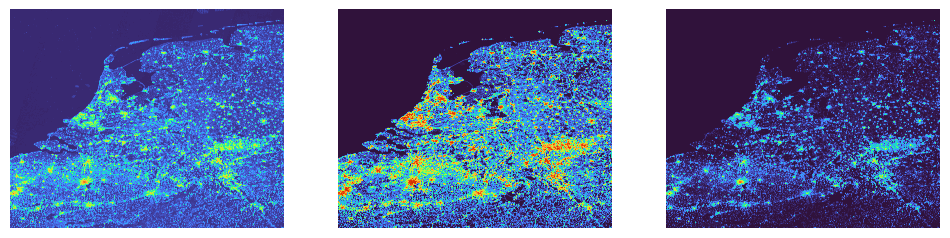

In [3]:
bounding_box = BoundingBox(
    minx=3.0,
    maxx=7.999999996,
    miny=50.000000004,
    maxy=54.0,
    mint=0.0,
    maxt=9.223372036854776e18,
)
sample = dataset[bounding_box]
print("input channels", sample["image"].shape[0])
print("mask channels", sample["mask"].shape[0])
print("mask values", torch.unique(sample["mask"]))
plot_input(sample, rows=1)


## Sampling map

Blue chips are one training batch, red one validation batch, green one test batch.
The split is 70 / 15 / 15 with the seed below. Change train/val/test batch parameters if you  want a quick look on another batch.
The OSM basemap needs a network connection. The chip outlines are still drawn if it fails.


Seed set to 54321
/mnt/c/Users/Dominika/Desktop/Code_for_AWS_data/PredictPS/.venv/lib/python3.9/site-packages/cartopy/mpl/style.py:76: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/mnt/c/Users/Dominika/Desktop/Code_for_AWS_data/PredictPS/.venv/lib/python3.9/site-packages/cartopy/mpl/style.py:76: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/mnt/c/Users/Dominika/Desktop/Code_for_AWS_data/PredictPS/.venv/lib/python3.9/site-packages/cartopy/mpl/style.py:76: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/mnt/c/Users/Dominika/Desktop/Code_for_AWS_data/PredictPS/.venv/lib/python3.9/site-packages/cartopy/mpl/style.py:76: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings

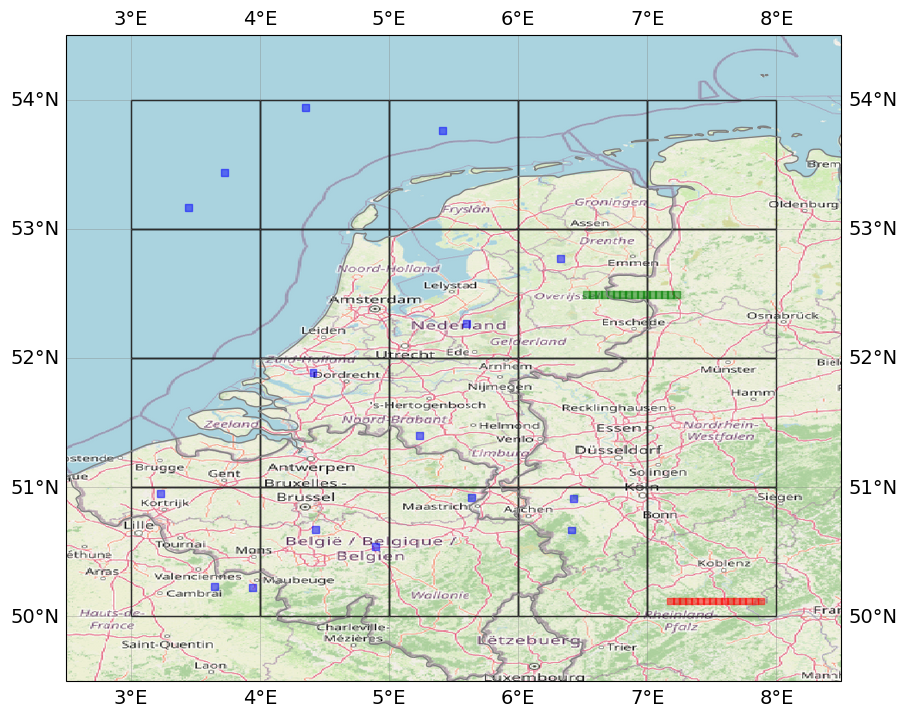

In [5]:
seed = 54321
patch_size = 64
batch_size = 16

fig = plot_sampling_map(
    dataset,
    seed=seed,
    patch_size=patch_size,
    batch_size=batch_size,
    train_batch=50,
    val_batch=5,
    test_batch=20,
    save_path=os.path.join(experiment_dir, "fig2.jpg"),
)


## Optional training

Same loop as `scripts/train.py`. Change `seed` or `param_opts` here, then run the cell.
Skip this cell if you only wanted the plots. Training needs a CUDA GPU.


In [8]:
in_channels = 2
ignore_index = None
lr_patience = 10
min_delta_lr = 0.01
patience = 15
min_delta = 0.01
max_epochs = 5 # change this to 300 for full training
gpu_id = 0
device = torch.device(f"cuda:{gpu_id}")
num_dataloader_workers = 0

param_const = [
    in_channels,
    ignore_index,
    lr_patience,
    min_delta_lr,
    patience,
    min_delta,
    max_epochs,
    gpu_id,
    device,
    num_dataloader_workers,
]
param_opts = [
    [16, 64, None, "resnet34", None, "mae", 0.00776601, 0.9, 0.99, 0.01],
]

for seed in [54321]:
    for i in range(len(param_opts)):
        trainer, task, datamodule = training_setup(
            seed, param_const, param_opts[i], dataset, experiment_dir, experiment_name
        )
        start_time = time.time()
        trainer.fit(model=task, datamodule=datamodule)
        print("Training took {:.2f} seconds".format(time.time() - start_time))
        new_name = "seed_{}_{}.ckpt".format(
            seed, datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
        )
        shutil.copy(
            trainer.checkpoint_callback.best_model_path,
            os.path.join(experiment_dir, new_name),
        )

print("Training done")


Seed set to 54321
Seed set to 54321
Seed set to 54321
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
Missing logger folder: /mnt/e/global_coh_map/00_data_to_be_published//trainingnn_results/pixel_wise_regression_model_training_updated_OSM/logs/pixel_wise_regression_model_training_updated_OSM_20261022-120627_seed54321
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name               | Type             | Params
--------------------------------------------------------
0 | model              | Unet             | 24.4 M
1 | loss               | L1Loss           | 0     
2 | train_metrics      | MetricCollection | 0     
3 | val_metrics        | MetricCollection | 0     
4 | test_metrics       | MetricCollection | 0     
5 | prediction_metrics | MetricCollection | 0     
--------------------------------------------------------
24.4 M    Trainabl

Epoch 4: 100%|██████████| 310/310 [02:21<00:00,  2.19it/s, v_num=0, val_loss=2.070, val_MAE=1.920, val_MSE=26.90, val_RMSE=5.190]

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 310/310 [02:32<00:00,  2.03it/s, v_num=0, val_loss=2.070, val_MAE=1.920, val_MSE=26.90, val_RMSE=5.190]
Training took 794.44 seconds
Training done
